# Pricing and exercise: define the target before trusting a number

This portable notebook runs **small current-source synthetic calculations** for European BS/Heston/rough Heston and American BS/Heston. It also reads a compact derivative of an earlier synthetic policy study. Fresh calculations and historical findings have different identities: no saved Monte Carlo pool or private archive is required.

Prices are dollars per underlying unit; contract multipliers belong outside the pricers. [Reading guide](README.md) · [Research findings](../reports/research_findings.md)

## 1. Specify the market and model

The fresh synthetic market has spot 100, a flat 4% discount rate and an explicitly empty expected cash-dividend schedule. A separate BS/Heston illustration adds a declared $1.50 cash dividend at .08 years. Those declarations are assumptions, not inferred market inputs. European APIs take explicit forwards and discounts; the American boundary takes spot, a discount curve and cash-dividend coverage.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/rvlab/pricing").is_dir())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
import rvlab
assert Path(rvlab.__file__).resolve().is_relative_to((ROOT / "src").resolve())
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import public_notebook_support as demo
demo.style()
SEED = 42

Matplotlib is building the font cache; this may take a moment.


In [2]:
from dataclasses import asdict
from rvlab.pricing import PricingConfig, FDConfig
display(pd.DataFrame([{"model":name, **asdict(params)} for name,params in demo.TRUTHS.items()]))
display(pd.DataFrame([{"role":"Fourier demonstration", **asdict(demo.FOURIER)},
    {"role":"Synthetic generation / finer comparison", **asdict(demo.FINE_FOURIER)}]))

,model,volatility,v0,theta,kappa,vol_of_vol,rho,hurst
0,Black–Scholes,0.2,NaN,NaN,NaN,NaN,NaN,NaN
1,Heston,NaN,0.04,0.045,1.5,0.30,-0.6,NaN
2,Rough Heston,NaN,0.04,0.045,1.0,0.12,-0.6,0.15


,role,quadrature_nodes,fourier_cutoff,riccati_steps
0,Fourier demonstration,96,100.0,256
1,Synthetic generation / finer comparison,192,200.0,512


## 2. European prices and implied-volatility smiles

The same contract can have different model prices because the variance dynamics differ. Implied volatility translates a call price into the BS volatility matching that price; it does not establish a new volatility process. Rough Heston uses the fractional kernel \(K_H(t)=t^{H-1/2}/\Gamma(H+1/2)\). The local fractional-Riccati/Fourier routine is distinct from the finite-factor American stopping approximation.

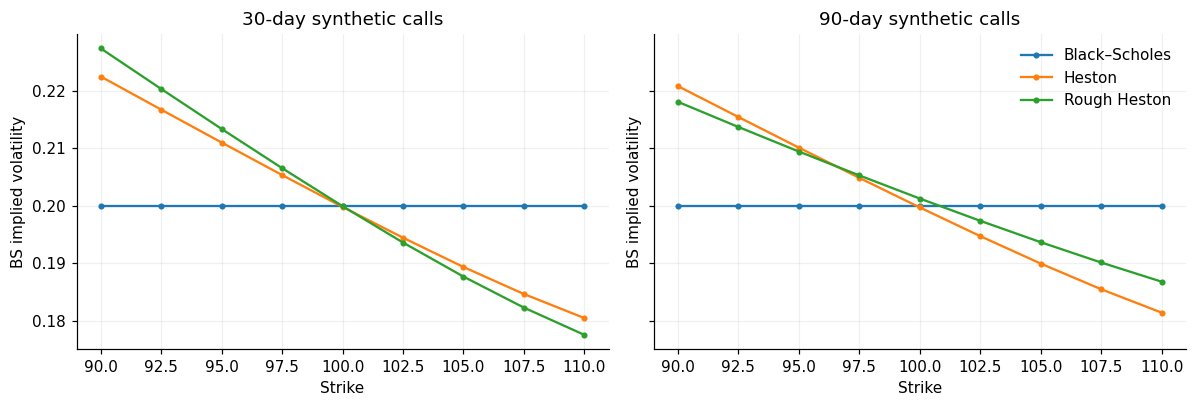

,,min_price,max_price
model,days,,
Black–Scholes,30,0.137892,10.356223
Heston,30,0.081692,10.404798
Rough Heston,30,0.074691,10.417554
Black–Scholes,90,1.117877,11.453207
Heston,90,0.863199,11.664134
Rough Heston,90,0.934901,11.635021


In [3]:
european_prices, smile_figure = demo.pricing_demo()
display(smile_figure)
plt.close(smile_figure)
display(european_prices.groupby(["model","days"], sort=False).agg(min_price=("price","min"), max_price=("price","max")))

## 3. American exercise and cash events

An exercise policy says **exercise or continue**, using information available now. Its value is the expected discounted payoff at its stopping time. The optimal American value is the supremum over admissible policies. BS/Heston finite differences solve an exercise constraint on their grids; simulation-based rough stopping learns a rule in a larger state.

The following fresh finite-difference examples display exercise premiums and stock deltas. Delta holds parameters, discounting and cash dividends fixed. Cash jumps follow capped limited liability. Starting grid budgets are demonstrations, not accuracy guarantees.

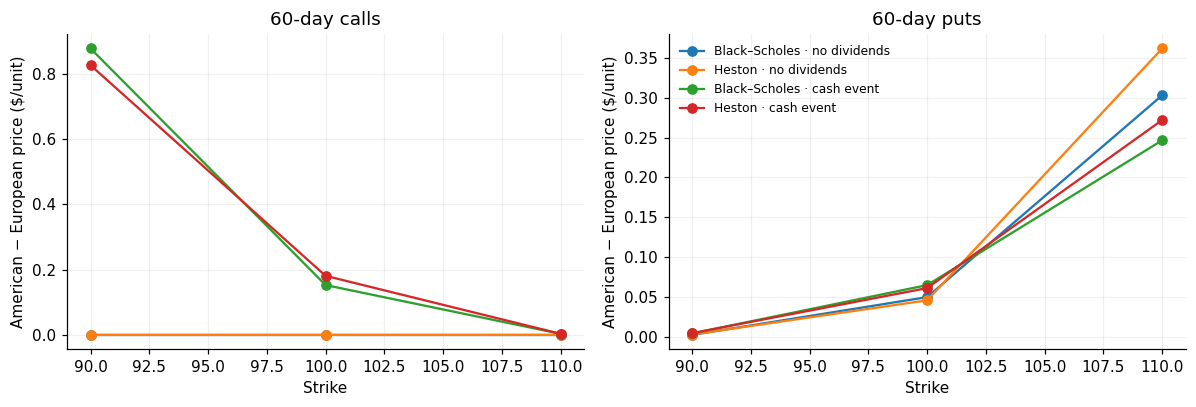

,market,model,option,strike,european,american,exercise_premium,stock_delta
1,Declared zero dividends,Black–Scholes,call,100.0,3.559633,3.559633,-4.329099e-09,0.548589
4,Declared zero dividends,Black–Scholes,put,100.0,2.904256,2.954303,5.004721e-02,-0.461740
7,Declared zero dividends,Heston,call,100.0,3.556397,3.556397,4.496277e-08,0.582549
10,Declared zero dividends,Heston,put,100.0,2.901020,2.947036,4.601619e-02,-0.427796
13,Cash dividend $1.50 at .08 years,Black–Scholes,call,100.0,2.819450,2.972175,1.527247e-01,0.515872
16,Cash dividend $1.50 at .08 years,Black–Scholes,put,100.0,3.659281,3.724362,6.508109e-02,-0.536926
19,Cash dividend $1.50 at .08 years,Heston,call,100.0,2.765486,2.946540,1.810536e-01,0.551598
22,Cash dividend $1.50 at .08 years,Heston,put,100.0,3.605317,3.666663,6.134585e-02,-0.504800


,model,price_change,price_allowance,delta_change,delta_allowance,price_check_pass,delta_check_pass
0,Black–Scholes,0.001915,0.001296,0.000021,0.004311,False,True
1,Heston,0.001774,0.001295,0.000284,0.004141,False,True


In [4]:
american_prices, fd_refinement, premium_figure = demo.american_controls()
display(premium_figure)
plt.close(premium_figure)
display(american_prices.loc[american_prices.strike.eq(100.)])
display(fd_refinement)

## 4. A useful exact American-call reduction

For calls with complete **zero-distribution coverage**, nonnegative deterministic forward rates, frictionless trading with no additional carry benefit, and a true-martingale discounted stock, early exercise has no value. The guarded `price_american_calls` API can therefore use the European transform while retaining the American exercise label. The market checks are explicit; a characteristic function returning one at a martingale argument does not itself prove the economic assumption.

This reduction supports rough-Heston **calls under these conditions**. It does not solve dividend-paying calls, American puts, historical rough states or stock Greeks.

In [5]:
display(demo.call_reduction_demo())

,model,american_call,european_call,difference,route
0,Black–Scholes,3.561753,3.561753,0.0,Guarded no-early-exercise reduction
1,Heston,3.557198,3.557198,0.0,Guarded no-early-exercise reduction
2,Rough Heston,3.572178,3.572178,0.0,Guarded no-early-exercise reduction


## 5. What the earlier rough exercise study established

The table below is **archived synthetic evidence**, not a calculation performed by this notebook. It compares full-state cashflow LSM, Fourier-premium LSM and one-interval Bellman lookahead on identical independent valuation paths. The conventional baseline is the source's all-state bounded-continuation variant, not every implementation of published LSM.

The Fourier proxy improved that naive baseline in six cases in each budget arm. Bellman added smaller gains, but cost more. Some cashflow rules lost to the known immediate-exercise alternative. **All 36 primary price budgets failed**, and adverse time/factor refinements remained. This is evidence about those implementations and finite simulated laws, not a universal algorithm ranking or optimal rough-American price certificate. Full saved paths and audit receipts remain in the local research archive.

In [6]:
archived_policies = demo.aggregate("synthetic_policy_values.csv")
display(archived_policies.groupby(["arm","policy"], sort=False).agg(
    cases=("case_id","size"), price_budget_passes=("price_budget_pass","sum")))
assert not archived_policies.price_budget_pass.any()

cases  price_budget_passes
arm               policy                                         
matched_paths     cashflow_lsm             6                    0
                  fourier_premium_lsm      6                    0
                  bellman_lookahead        6                    0
matched_allowance cashflow_lsm             6                    0
                  fourier_premium_lsm      6                    0
                  bellman_lookahead        6                    0

## 6. Read the error budget in layers

Kernel approximation, discrete dynamics, exercise dates, policy approximation and Monte Carlo uncertainty are different errors. A narrow sampling interval need not mean a good exercise rule; a wide lower/upper bracket can combine policy loss and loose dual estimation. The original price tolerance remains `.001 + 1e-4 |V|`; stock-delta checks use `.002 + .005 |delta|`. This notebook's two-grid FD check is only one direction, not a general convergence proof.

European synthetic pricing and the guarded call reduction are available for further experiments. General rough-American stopping accuracy, calibrated historical state and portfolio hedging remain open. [Notebook 02](02_synthetic_calibration.ipynb) tests small synthetic price recovery. [Notebook 03](03_spy_pilot.ipynb) distinguishes the archived SPY pilot from live recomputation.